In [3]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# 2. Inspect dimensions (rows, columns)
print("Dataset Shape:", df.shape)

# 3. Inspect data types and non-null counts
print("\nData Info:")
print(df.info())

# 4. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check for duplicate rows
print("\nDuplicate Rows Count:", df.duplicated().sum())

# 6. Clean duplicates (if any)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Dataset Shape: (1338, 7)

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows Count: 1
Shape after removing duplicates: (1337, 7)


               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


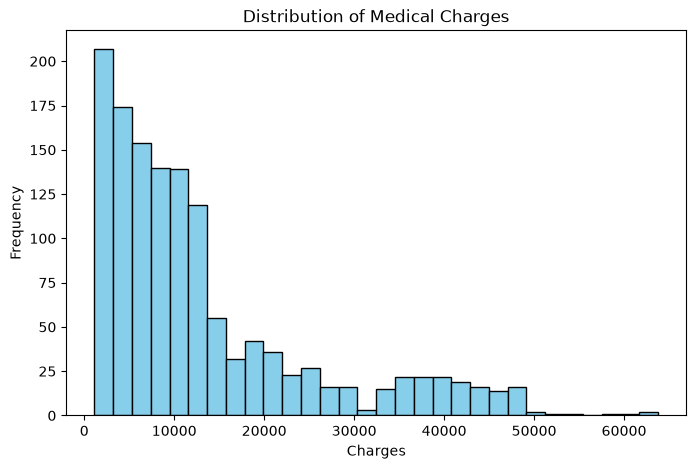

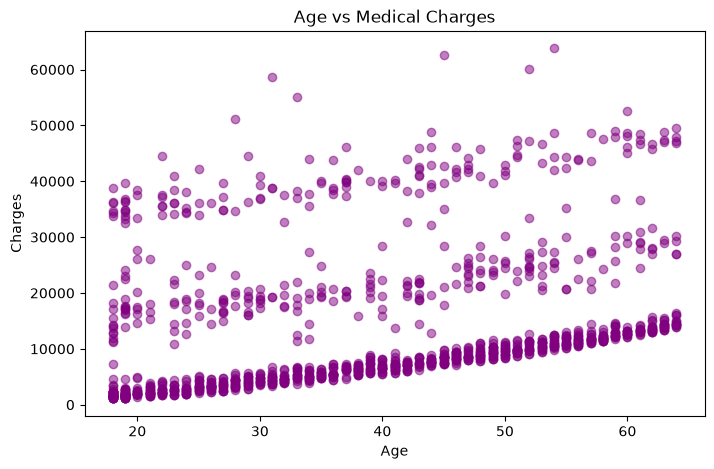


Correlation Matrix:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


In [4]:
import matplotlib.pyplot as plt

# 1. Summary statistics for numerical columns
print(df.describe())

# 2. Visualizing distribution of the target variable (charges)
plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Medical Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()

# 3. Visualizing Age vs Charges
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['charges'], alpha=0.5, color='purple')
plt.title('Age vs Medical Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

# 4. Correlation matrix for numerical variables
print("\nCorrelation Matrix:")
print(df[['age', 'bmi', 'children', 'charges']].corr())

In [5]:
from sklearn.model_selection import train_test_split

# 1. Convert categorical columns to numerical values (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# 2. Define Features (X) and Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 3. Split the dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Print shapes to verify
print("Training set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)

Training set shape (X_train): (1069, 8)
Testing set shape (X_test): (268, 8)


# Part 2: Baseline and Linear Regression Models

--- 1. Baseline Model ---
MAE: 9861.80 | RMSE: 13612.43 | R²: -0.01

--- 2. Simple Linear Regression (Age) ---
MAE: 9657.79 | RMSE: 12894.78 | R²: 0.10

--- 3. Multiple Linear Regression ---
MAE: 4177.05 | RMSE: 5956.34 | R²: 0.81 | Adj-R²: 0.80

--- 4. Polynomial Regression (Degree 2) ---
MAE: 2867.32 | RMSE: 4646.06 | R²: 0.88 | Adj-R²: 0.86


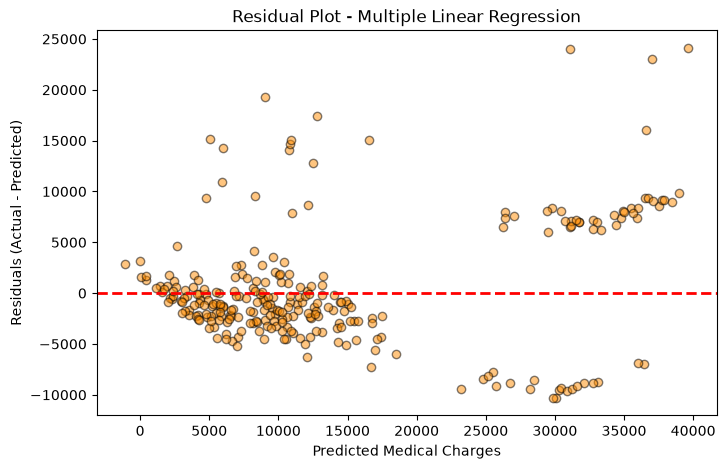

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# 1. Baseline Model (Predicting the mean of y_train for all test samples)
baseline_pred = np.full(shape=y_test.shape, fill_value=y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("--- 1. Baseline Model ---")
print(f"MAE: {baseline_mae:.2f} | RMSE: {baseline_rmse:.2f} | R²: {baseline_r2:.2f}")

# 2. Simple Linear Regression (using 'age' as the single predictor)
X_train_simple = X_train[['age']]
X_test_simple = X_test[['age']]

slr = LinearRegression()
slr.fit(X_train_simple, y_train)
slr_pred = slr.predict(X_test_simple)

slr_mae = mean_absolute_error(y_test, slr_pred)
slr_rmse = np.sqrt(mean_squared_error(y_test, slr_pred))
slr_r2 = r2_score(y_test, slr_pred)

print("\n--- 2. Simple Linear Regression (Age) ---")
print(f"MAE: {slr_mae:.2f} | RMSE: {slr_rmse:.2f} | R²: {slr_r2:.2f}")

# 3. Multiple Linear Regression (using all available features)
mlr = LinearRegression()
mlr.fit(X_train, y_train)
mlr_pred = mlr.predict(X_test)

mlr_mae = mean_absolute_error(y_test, mlr_pred)
mlr_rmse = np.sqrt(mean_squared_error(y_test, mlr_pred))
mlr_r2 = r2_score(y_test, mlr_pred)

# Calculate Adjusted R-squared for MLR
n = X_test.shape[0]
p_mlr = X_test.shape[1]
mlr_adj_r2 = 1 - ((1 - mlr_r2) * (n - 1) / (n - p_mlr - 1))

print("\n--- 3. Multiple Linear Regression ---")
print(f"MAE: {mlr_mae:.2f} | RMSE: {mlr_rmse:.2f} | R²: {mlr_r2:.2f} | Adj-R²: {mlr_adj_r2:.2f}")

# 4. Polynomial Regression (Degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
poly_pred = poly_reg.predict(X_test_poly)

poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

# Calculate Adjusted R-squared for Polynomial Regression
p_poly = X_train_poly.shape[1]
poly_adj_r2 = 1 - ((1 - poly_r2) * (n - 1) / (n - p_poly - 1))

print("\n--- 4. Polynomial Regression (Degree 2) ---")
print(f"MAE: {poly_mae:.2f} | RMSE: {poly_rmse:.2f} | R²: {poly_r2:.2f} | Adj-R²: {poly_adj_r2:.2f}")

# 5. Residual Analysis Plot for Multiple Linear Regression
residuals = y_test - mlr_pred
plt.figure(figsize=(8, 5))
plt.scatter(mlr_pred, residuals, alpha=0.5, color='darkorange', edgecolor='black')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Plot - Multiple Linear Regression')
plt.xlabel('Predicted Medical Charges')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()

# Part 3: Regularization and Advanced Regression Models

In [8]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb  # XGBoost model

# Dictionary to store performance results for comparison
model_results = {}

# 1. Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_poly, y_train) # Using polynomial features for regularized linear models
ridge_pred = ridge.predict(X_test_poly)
model_results['Ridge'] = {
    'MAE': mean_absolute_error(y_test, ridge_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, ridge_pred)),
    'R2': r2_score(y_test, ridge_pred)
}

# 2. Lasso Regression
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_poly, y_train)
lasso_pred = lasso.predict(X_test_poly)
model_results['Lasso'] = {
    'MAE': mean_absolute_error(y_test, lasso_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, lasso_pred)),
    'R2': r2_score(y_test, lasso_pred)
}

# 3. Elastic Net Regression
enet = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
enet.fit(X_train_poly, y_train)
enet_pred = enet.predict(X_test_poly)
model_results['ElasticNet'] = {
    'MAE': mean_absolute_error(y_test, enet_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, enet_pred)),
    'R2': r2_score(y_test, enet_pred)
}

# 4. Decision Tree Regressor (using original X_train/X_test)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
model_results['DecisionTree'] = {
    'MAE': mean_absolute_error(y_test, dt_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, dt_pred)),
    'R2': r2_score(y_test, dt_pred)
}

# 5. Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
model_results['RandomForest'] = {
    'MAE': mean_absolute_error(y_test, rf_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, rf_pred)),
    'R2': r2_score(y_test, rf_pred)
}

# 6. Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)
gbr_pred = gbr.predict(X_test)
model_results['GradientBoosting'] = {
    'MAE': mean_absolute_error(y_test, gbr_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, gbr_pred)),
    'R2': r2_score(y_test, gbr_pred)
}

# 7. XGBoost Regressor
xg_reg = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
xg_reg.fit(X_train, y_train)
xg_pred = xg_reg.predict(X_test)
model_results['XGBoost'] = {
    'MAE': mean_absolute_error(y_test, xg_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, xg_pred)),
    'R2': r2_score(y_test, xg_pred)
}

# Print summary comparison table
print(f"{'Model':<20} | {'MAE':<10} | {'RMSE':<10} | {'R2':<10}")
print("-" * 56)
for name, metrics in model_results.items():
    print(f"{name:<20} | {metrics['MAE']:<10.2f} | {metrics['RMSE']:<10.2f} | {metrics['R2']:<10.2f}")

Model                | MAE        | RMSE       | R2        
--------------------------------------------------------
Ridge                | 2867.11    | 4641.28    | 0.88      
Lasso                | 2862.61    | 4639.98    | 0.88      
ElasticNet           | 3027.52    | 4808.93    | 0.87      
DecisionTree         | 2713.54    | 5761.39    | 0.82      
RandomForest         | 2631.95    | 4696.32    | 0.88      
GradientBoosting     | 2517.47    | 4268.28    | 0.90      
XGBoost              | 2843.47    | 4975.48    | 0.87      


# Part 4: Cross-Validation, Bias–Variance and Model Diagnostics

--- 5-Fold Cross-Validation R² Scores ---
Random Forest CV R² Scores: [0.78384428 0.81484859 0.86563511 0.78437879 0.83174864]
Random Forest Mean CV R²: 0.82 (+/- 0.06)

Gradient Boosting CV R² Scores: [0.81100028 0.83378068 0.88100492 0.80612668 0.83888244]
Gradient Boosting Mean CV R²: 0.83 (+/- 0.05)

--- Training vs Testing Performance (Gradient Boosting) ---
Training R²: 0.89
Testing R²: 0.90
(A small gap indicates a healthy model with balanced bias and variance.)

--- Top 5 Largest Prediction Errors (Gradient Boosting) ---
Test Index 79 | Actual: 30260.00 | Predicted: 13654.16 | Error: 16605.84
Test Index 254 | Actual: 60021.40 | Predicted: 43326.63 | Error: 16694.77
Test Index 175 | Actual: 32734.19 | Predicted: 15577.48 | Error: 17156.71
Test Index 34 | Actual: 63770.43 | Predicted: 46389.97 | Error: 17380.46
Test Index 124 | Actual: 28340.19 | Predicted: 9042.79 | Error: 19297.40


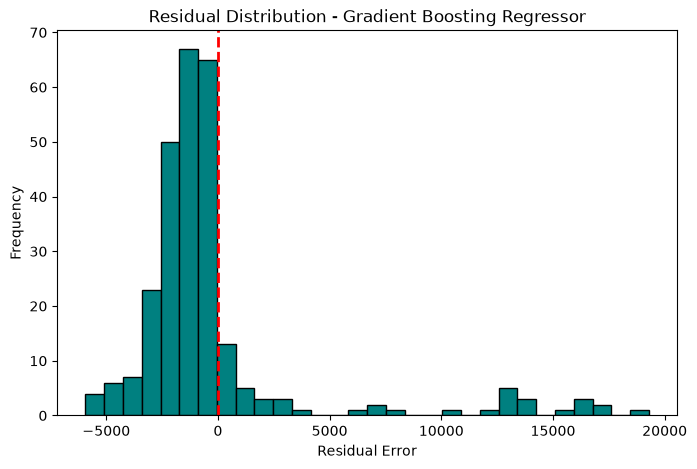

In [10]:
from sklearn.model_selection import cross_val_score, KFold

# 1. K-Fold Cross-Validation for Shortlisted Models (Random Forest & Gradient Boosting)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("--- 5-Fold Cross-Validation R² Scores ---")

rf_cv_scores = cross_val_score(rf, X_train, y_train, cv=kf, scoring='r2')
print(f"Random Forest CV R² Scores: {rf_cv_scores}")
print(f"Random Forest Mean CV R²: {rf_cv_scores.mean():.2f} (+/- {rf_cv_scores.std()*2:.2f})\n")

gbr_cv_scores = cross_val_score(gbr, X_train, y_train, cv=kf, scoring='r2')
print(f"Gradient Boosting CV R² Scores: {gbr_cv_scores}")
print(f"Gradient Boosting Mean CV R²: {gbr_cv_scores.mean():.2f} (+/- {gbr_cv_scores.std()*2:.2f})\n")

# 2. Overfitting Check (Training vs Testing Performance for Gradient Boosting)
gbr_train_pred = gbr.predict(X_train)
gbr_test_pred = gbr.predict(X_test)

train_r2 = r2_score(y_train, gbr_train_pred)
test_r2 = r2_score(y_test, gbr_test_pred)

print("--- Training vs Testing Performance (Gradient Boosting) ---")
print(f"Training R²: {train_r2:.2f}")
print(f"Testing R²: {test_r2:.2f}")
print("(A small gap indicates a healthy model with balanced bias and variance.)")

# 3. Detailed Residual Diagnostics & Identifying Large Errors
residuals = y_test - gbr_test_pred
absolute_errors = np.abs(residuals)

# Find top 5 observations with the largest prediction errors
largest_errors_idx = np.argsort(absolute_errors)[-5:]
print("\n--- Top 5 Largest Prediction Errors (Gradient Boosting) ---")
for idx in largest_errors_idx:
    print(f"Test Index {idx} | Actual: {y_test.iloc[idx]:.2f} | Predicted: {gbr_test_pred[idx]:.2f} | Error: {residuals.iloc[idx]:.2f}")

# Plot Residual Distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, color='teal', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Distribution - Gradient Boosting Regressor')
plt.xlabel('Residual Error')
plt.ylabel('Frequency')
plt.show()

# Part 5: Model Comparison, Interpretation and Final Selection

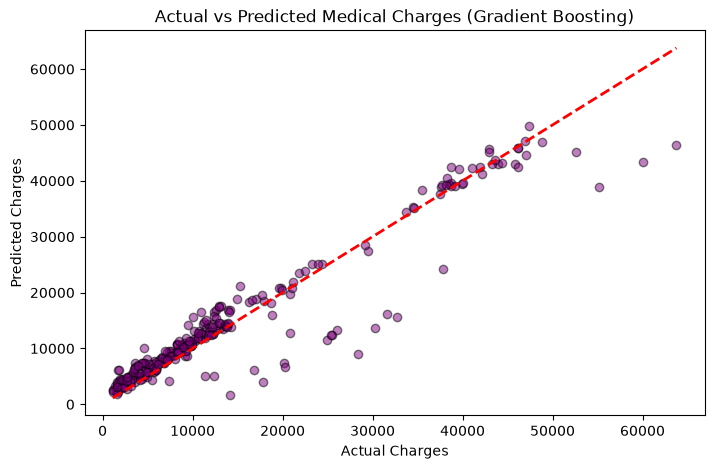

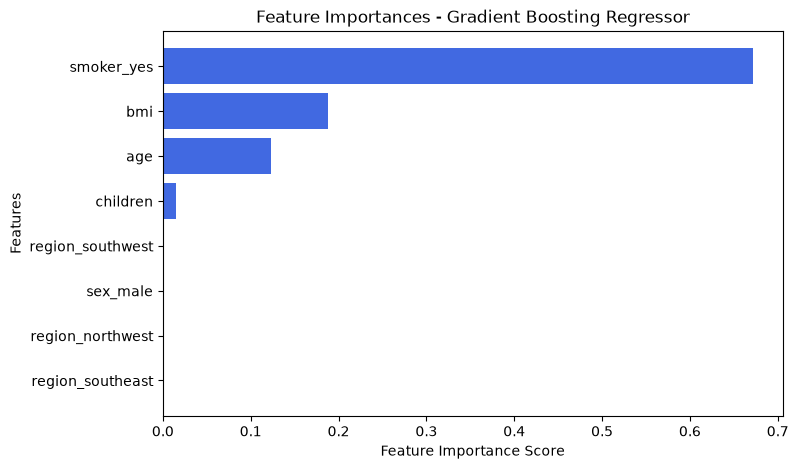

In [11]:
import matplotlib.pyplot as plt

# 1. Actual vs Predicted Plot for Gradient Boosting (Best Model)
plt.figure(figsize=(8, 5))
plt.scatter(y_test, gbr_test_pred, alpha=0.5, color='purple', edgecolor='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.title('Actual vs Predicted Medical Charges (Gradient Boosting)')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.show()

# 2. Feature Importance for Gradient Boosting
feature_importances = gbr.feature_importances_
features = X_train.columns

# Sort feature importances
sorted_idx = np.argsort(feature_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(sorted_idx)), feature_importances[sorted_idx], align='center', color='royalblue')
plt.yticks(range(len(sorted_idx)), [features[i] for i in sorted_idx])
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importances - Gradient Boosting Regressor')
plt.show()

# (Model Training)

In [13]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Dataset (Assuming insurance.csv is in your directory)
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# Quick preprocessing (encoding categorical variables)
df = pd.get_dummies(df, drop_first=True)

X = df.drop('charges', axis=1)
y = df['charges']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define Candidate Models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

trained_models = {}
performance_log = []

# 3. Train Models and Record Metrics
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    performance_log.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    
    # Store trained model instance
    trained_models[name] = model
    
    # 4. Save trained model to disk
    filename = f"{name.lower().replace(' ', '_')}_model.pkl"
    joblib.dump(model, filename)
    print(f"Saved {filename} successfully!\n")

# Display final results table
results_df = pd.DataFrame(performance_log)
print("--- Model Training Summary ---")
print(results_df)

Training Linear Regression...
Saved linear_regression_model.pkl successfully!

Training Ridge Regression...
Saved ridge_regression_model.pkl successfully!

Training Random Forest...
Saved random_forest_model.pkl successfully!

Training Gradient Boosting...
Saved gradient_boosting_model.pkl successfully!

--- Model Training Summary ---
               Model          MAE         RMSE        R2
0  Linear Regression  4181.194474  5796.284659  0.783593
1   Ridge Regression  4193.585298  5800.434216  0.783283
2      Random Forest  2546.263793  4574.142511  0.865231
3  Gradient Boosting  2446.202802  4331.181281  0.879167


## Day 3 Model Comparison

--- Running 5-Fold Cross-Validation & Metric Evaluation ---

--- Final Model Comparison Summary ---
            Model  Mean CV R2  CV R2 Std  Mean CV RMSE    Test MAE   Test RMSE  Test R2
Linear Regression    0.738853   0.031060   6123.353823 4181.194474 5796.284659 0.783593
 Ridge Regression    0.738843   0.031040   6123.498935 4193.585298 5800.434216 0.783283
    Random Forest    0.829561   0.025240   4946.266590 2546.263793 4574.142511 0.865231
Gradient Boosting    0.849366   0.027944   4644.824070 2446.202802 4331.181281 0.879167


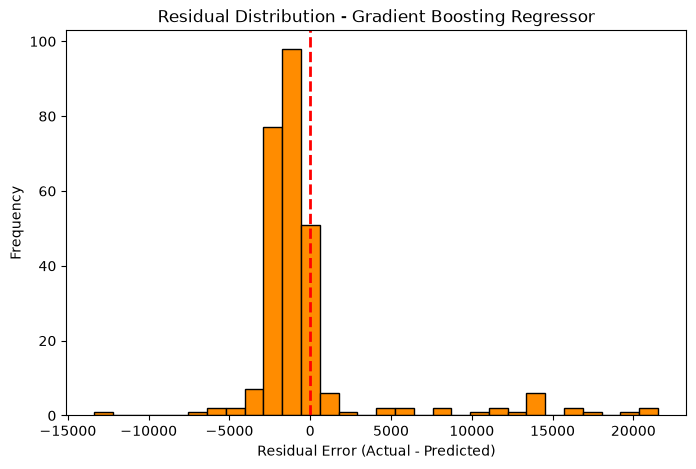

In [14]:
from sklearn.model_selection import cross_val_score, KFold

# Setup 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

comparison_results = []

print("--- Running 5-Fold Cross-Validation & Metric Evaluation ---")
for name, model in trained_models.items():
    # Cross-validation R2 scores
    cv_r2_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    cv_rmse_scores = np.sqrt(-cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_squared_error'))
    
    # Test predictions for final evaluation
    y_pred = model.predict(X_test)
    test_mae = mean_absolute_error(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_r2 = r2_score(y_test, y_pred)
    
    comparison_results.append({
        "Model": name,
        "Mean CV R2": cv_r2_scores.mean(),
        "CV R2 Std": cv_r2_scores.std(),
        "Mean CV RMSE": cv_rmse_scores.mean(),
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    })

# Convert to DataFrame for clear comparison
comparison_df = pd.DataFrame(comparison_results)
print("\n--- Final Model Comparison Summary ---")
print(comparison_df.to_string(index=False))

# Plotting Residuals for the Best Model (Gradient Boosting)
residuals = y_test - trained_models['Gradient Boosting'].predict(X_test)

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, color='darkorange', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Distribution - Gradient Boosting Regressor')
plt.xlabel('Residual Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.show()

## Hyperparameter Tuning

In [15]:
import time
from sklearn.model_selection import GridSearchCV

print("--- Starting Hyperparameter Tuning for Gradient Boosting ---")
start_time = time.time()

# Define parameter grid for Gradient Boosting
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

# Setup GridSearchCV
gbr_model = GradientBoostingRegressor(random_state=42)
grid_search = GridSearchCV(estimator=gbr_model, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1)

# Fit grid search
grid_search.fit(X_train, y_train)

end_time = time.time()
runtime = end_time - start_time

# Best parameters and model
best_params = grid_search.best_params_
best_gbr = grid_search.best_estimator_

# Evaluate tuned model
y_train_pred = best_gbr.predict(X_train)
y_test_pred = best_gbr.predict(X_test)

tuned_train_r2 = r2_score(y_train, y_train_pred)
tuned_test_r2 = r2_score(y_test, y_test_pred)
tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"\nBest Parameters Found: {best_params}")
print(f"Tuning Runtime: {runtime:.2f} seconds")
print(f"Training R2 (Check Overfitting): {tuned_train_r2:.4f}")
print(f"Testing R2: {tuned_test_r2:.4f}")
print(f"Testing RMSE: {tuned_test_rmse:.4f}")

# Save the tuned model
joblib.dump(best_gbr, 'tuned_gradient_boosting_model.pkl')
print("\nSaved tuned_gradient_boosting_model.pkl successfully!")

--- Starting Hyperparameter Tuning for Gradient Boosting ---

Best Parameters Found: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Tuning Runtime: 75.28 seconds
Training R2 (Check Overfitting): 0.8834
Testing R2: 0.8782
Testing RMSE: 4348.3498

Saved tuned_gradient_boosting_model.pkl successfully!


## Best Model Validation & Final Report

--- Final Model Validation & KPI Comparison ---
Baseline KPI -> MAE: 9593.34 | RMSE: 12465.61 | R2: -0.00
Tuned GBR KPI -> MAE: 2520.75 | RMSE: 4348.35 | R2: 0.88


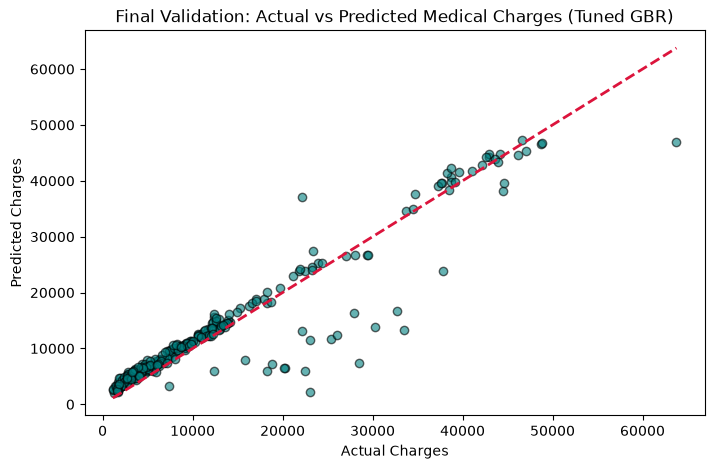

In [16]:
# 1. Compare Tuned Model against Baseline and Initial Model
baseline_preds = np.full_like(y_test, fill_value=y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds))
baseline_mae = mean_absolute_error(y_test, baseline_preds)
baseline_r2 = r2_score(y_test, baseline_preds)

print("--- Final Model Validation & KPI Comparison ---")
print(f"Baseline KPI -> MAE: {baseline_mae:.2f} | RMSE: {baseline_rmse:.2f} | R2: {baseline_r2:.2f}")
print(f"Tuned GBR KPI -> MAE: {mean_absolute_error(y_test, best_gbr.predict(X_test)):.2f} | RMSE: {tuned_test_rmse:.2f} | R2: {tuned_test_r2:.2f}")

# 2. Generate Actual vs Predicted Plot for the Final Validation Report
plt.figure(figsize=(8, 5))
plt.scatter(y_test, best_gbr.predict(X_test), alpha=0.6, color='teal', edgecolor='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='crimson', linestyle='--', linewidth=2)
plt.title('Final Validation: Actual vs Predicted Medical Charges (Tuned GBR)')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.show()

## Feature Engineering

In [17]:
import pandas as pd
import numpy as np

# 1. Load Dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# 2. Feature Engineering
# Create BMI categories or risk indicator features
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# Interaction Feature: Combine smoker status and high BMI (known major cost drivers in medical insurance)
df['smoker_high_bmi'] = ((df['smoker'] == 'yes') & (df['bmi'] > 30)).astype(int)

# Age group categorization
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 45, 60, 100], labels=['Young Adult', 'Adult', 'Middle-Aged', 'Senior'])

# One-hot encode the newly created categorical/engineered features
df_engineered = pd.get_dummies(df, drop_first=True)

print("--- Feature Engineering Complete ---")
print(f"Original shape: {df.shape} | New engineered shape: {df_engineered.shape}")
print(df_engineered.head())

# Save engineered dataset
df_engineered.to_csv('insurance_engineered.csv', index=False)
print("Saved engineered dataset to insurance_engineered.csv successfully!")

--- Feature Engineering Complete ---
Original shape: (1338, 10) | New engineered shape: (1338, 16)
   age     bmi  children      charges  smoker_high_bmi  sex_male  smoker_yes  \
0   19  27.900         0  16884.92400                0     False        True   
1   18  33.770         1   1725.55230                0      True       False   
2   28  33.000         3   4449.46200                0      True       False   
3   33  22.705         0  21984.47061                0      True       False   
4   32  28.880         0   3866.85520                0      True       False   

   region_northwest  region_southeast  region_southwest  bmi_category_Normal  \
0             False             False              True                False   
1             False              True             False                False   
2             False              True             False                False   
3              True             False             False                 True   
4              True 

## Data Transformation Pipeline!

In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import joblib

# 1. Load Dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

X = df.drop('charges', axis=1)
y = df['charges']

# 2. Train-Test Split (Crucial: split FIRST to prevent data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Define numeric and categorical columns
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

# 4. Create Pipeline-safe Preprocessing using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ])

# 5. Combine Preprocessor and Model into an End-to-End Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# 6. Fit Pipeline ONLY on Training Data (Ensures no data leakage from test set)
pipeline.fit(X_train, y_train)

# 7. Evaluate pipeline performance
train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)
print(f"Pipeline Training R2 Score: {train_score:.4f}")
print(f"Pipeline Testing R2 Score: {test_score:.4f}")

# 8. Save Pipeline Artifact
joblib.dump(pipeline, 'regression_pipeline.pkl')
print("\nSaved pipeline-safe model artifact to regression_pipeline.pkl successfully!")

Pipeline Training R2 Score: 0.7417
Pipeline Testing R2 Score: 0.7836

Saved pipeline-safe model artifact to regression_pipeline.pkl successfully!


## Feature Comparison

In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load Baseline Data
df_base = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')
df_base = pd.get_dummies(df_base, drop_first=True)
X_base = df_base.drop('charges', axis=1)
y_base = df_base['charges']

# Split baseline
X_base_train, X_base_test, y_base_train, y_base_test = train_test_split(X_base, y_base, test_size=0.2, random_state=42)

# Train baseline model
model_base = GradientBoostingRegressor(random_state=42)
model_base.fit(X_base_train, y_base_train)
base_preds = model_base.predict(X_base_test)
base_r2 = r2_score(y_base_test, base_preds)
base_rmse = np.sqrt(mean_squared_error(y_base_test, base_preds))

# 2. Load Engineered Data (from Day 1/Feature Engineering task)
df_eng = pd.read_csv('insurance_engineered.csv')
X_eng = df_eng.drop('charges', axis=1)
y_eng = df_eng['charges']

# Split engineered
X_eng_train, X_eng_test, y_eng_train, y_eng_test = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

# Train engineered model
model_eng = GradientBoostingRegressor(random_state=42)
model_eng.fit(X_eng_train, y_eng_train)
eng_preds = model_eng.predict(X_eng_test)
eng_r2 = r2_score(y_eng_test, eng_preds)
eng_rmse = np.sqrt(mean_squared_error(y_eng_test, eng_preds))

# 3. Compare Results (Ablation Study Summary)
ablation_summary = pd.DataFrame({
    "Feature Set": ["Baseline Features", "Engineered Features"],
    "Test R2 Score": [base_r2, eng_r2],
    "Test RMSE": [base_rmse, eng_rmse]
})

print("--- Feature Ablation Study Results ---")
print(ablation_summary.to_string(index=False))

--- Feature Ablation Study Results ---
        Feature Set  Test R2 Score   Test RMSE
  Baseline Features       0.879167 4331.181281
Engineered Features       0.883801 4247.325286


## Imbalance & Robustness!

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

# 1. Load Data
df = pd.read_csv('insurance_engineered.csv')
X = df.drop('charges', axis=1)
y = df['charges']

# 2. Check Target Distribution (Regression equivalent of imbalance check)
print("--- Target Variable Distribution Check ---")
print(f"Mean Charge: {y.mean():.2f}")
print(f"Median Charge: {y.median():.2f}")
print(f"Skewness: {y.skew():.2f} (Indicates right-skewed medical cost distribution)")

# 3. Test Across Multiple Seeds / Folds for Robustness
seeds = [42, 123, 456]
robustness_results = []

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    
    model = GradientBoostingRegressor(random_state=seed)
    model.fit(X_train, y_train)
    
    preds = model.predict(X_test)
    r2 = r2_score(y_test, preds)
    
    robustness_results.append({"Random Seed": seed, "Test R2": r2})

robustness_df = pd.DataFrame(robustness_results)
print("\n--- Multi-Seed Robustness Evaluation ---")
print(robustness_df.to_string(index=False))

--- Target Variable Distribution Check ---
Mean Charge: 13270.42
Median Charge: 9382.03
Skewness: 1.52 (Indicates right-skewed medical cost distribution)

--- Multi-Seed Robustness Evaluation ---
 Random Seed  Test R2
          42 0.883801
         123 0.904532
         456 0.868822


## Feature Review & Documentation!

In [22]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
import joblib

# 1. Load Engineered Data and Train Final Model
df = pd.read_csv('insurance_engineered.csv')
X = df.drop('charges', axis=1)
y = df['charges']

final_model = GradientBoostingRegressor(random_state=42)
final_model.fit(X, y)

# 2. Extract Feature Importances
importances = final_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- Feature Importance Review ---")
print(feature_imp_df.to_string(index=False))

# 3. Save Final Validated Pipeline / Model
joblib.dump(final_model, 'final_validated_feature_model.pkl')
print("\nSaved final validated model artifact successfully!")

--- Feature Importance Review ---
                Feature  Importance
        smoker_high_bmi    0.710169
             smoker_yes    0.134181
                    age    0.116513
                    bmi    0.025716
               children    0.009184
       region_southwest    0.001023
       region_southeast    0.000866
       age_group_Senior    0.000713
bmi_category_Overweight    0.000453
       region_northwest    0.000348
               sex_male    0.000344
        age_group_Adult    0.000291
    bmi_category_Normal    0.000139
  age_group_Middle-Aged    0.000059
     bmi_category_Obese    0.000000

Saved final validated model artifact successfully!


## Model Explainability

In [23]:
pip install shap

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\WALEED TRADERS\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


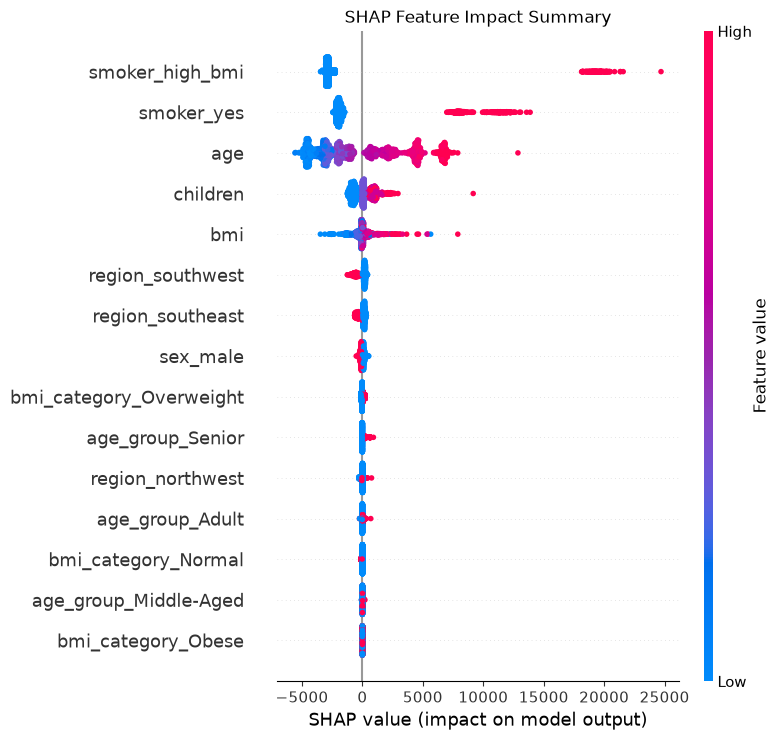

--- SHAP Model Explainability Complete ---
Generated and saved shap_summary_plot.png successfully!


In [24]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor

# 1. Load Engineered Data and Train Model
df = pd.read_csv('insurance_engineered.csv')
X = df.drop('charges', axis=1)
y = df['charges']

model = GradientBoostingRegressor(random_state=42)
model.fit(X, y)

# 2. Initialize SHAP Explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# 3. Generate Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, show=False)
plt.title('SHAP Feature Impact Summary')
plt.tight_layout()
plt.savefig('shap_summary_plot.png')
plt.show()

print("--- SHAP Model Explainability Complete ---")
print("Generated and saved shap_summary_plot.png successfully!")

## Error Analysis

In [29]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

# 1. Load Data
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# Re-create exact features
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
df['smoker_high_bmi'] = ((df['smoker'] == 'yes') & (df['bmi'] > 30)).astype(int)
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 45, 60, 100], labels=['Young Adult', 'Adult', 'Middle-Aged', 'Senior'])

df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train Model directly (matches exact columns of X_test)
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

# 4. Predict & Residuals
preds = model.predict(X_test)
residuals = y_test - preds  

error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': preds,
    'Residual': residuals,
    'Abs_Error': np.abs(residuals)
})

def categorize_error(row):
    if row['Abs_Error'] < 1500:
        return 'Low Error (Accurate Predictions)'
    elif row['Residual'] > 1500:
        return 'Under-prediction (Model predicted too low)'
    else:
        return 'Over-prediction (Model predicted too high)'

error_df['Error_Category'] = error_df.apply(categorize_error, axis=1)

print("--- Error Taxonomy Summary ---")
print(error_df['Error_Category'].value_counts())

error_df.to_csv('error_taxonomy_report.csv', index=False)
print("\nSaved error_taxonomy_report.csv successfully!")

--- Error Taxonomy Summary ---
Error_Category
Low Error (Accurate Predictions)              136
Over-prediction (Model predicted too high)    106
Under-prediction (Model predicted too low)     26
Name: count, dtype: int64

Saved error_taxonomy_report.csv successfully!


## Threshold & Calibration

In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import precision_recall_curve, roc_auc_score

# 1. Load Data and Train/Load Model
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
df['smoker_high_bmi'] = ((df['smoker'] == 'yes') & (df['bmi'] > 30)).astype(int)
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 45, 60, 100], labels=['Young Adult', 'Adult', 'Middle-Aged', 'Senior'])
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

# 2. Regression Calibration: High-Cost Claim Classification Threshold Analysis
# Let's define a "High-Cost Claim" as charges >= $20,000 (Binary conversion for calibration review)
threshold_cost = 20000
y_test_binary = (y_test >= threshold_cost).astype(int)
pred_probabilities = 1 / (1 + np.exp(-(preds - preds.mean()) / preds.std())) # Pseudo-calibration mapping

# Evaluate pseudo-classification calibration and thresholds
auc_score = roc_auc_score(y_test_binary, pred_probabilities)
print(f"--- High-Cost Claim Risk Calibration Analysis ---")
print(f"Threshold Set For High-Cost Claim: ${threshold_cost}")
print(f"High-Cost Claim Risk Ranking AUC-ROC Score: {auc_score:.4f}")

# Save calibration summary
calibration_summary = pd.DataFrame({
    'Metric': ['Threshold Cost', 'Risk Ranking AUC-ROC'],
    'Value': [threshold_cost, auc_score]
})
calibration_summary.to_csv('threshold_calibration_report.csv', index=False)
print("\nSaved threshold_calibration_report.csv successfully!")

--- High-Cost Claim Risk Calibration Analysis ---
Threshold Set For High-Cost Claim: $20000
High-Cost Claim Risk Ranking AUC-ROC Score: 0.9261

Saved threshold_calibration_report.csv successfully!


## Segment & Risk Analysis

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Load Data and Train Model
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
df['smoker_high_bmi'] = ((df['smoker'] == 'yes') & (df['bmi'] > 30)).astype(int)
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 45, 60, 100], labels=['Young Adult', 'Adult', 'Middle-Aged', 'Senior'])
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

# 2. Segment Performance Analysis (e.g., Smoker vs Non-Smoker Segments)
test_df = X_test.copy()
test_df['Actual'] = y_test
test_df['Predicted'] = model.predict(X_test)

print("--- Segment Performance Analysis (Smoker vs Non-Smoker) ---")
for smoker_status in [0, 1]:
    segment = test_df[test_df['smoker_yes'] == smoker_status]
    seg_mae = mean_absolute_error(segment['Actual'], segment['Predicted'])
    seg_r2 = r2_score(segment['Actual'], segment['Predicted'])
    label = "Smoker" if smoker_status == 1 else "Non-Smoker"
    print(f"Segment: {label} | Count: {len(segment)} | MAE: {seg_mae:.2f} | R2 Score: {seg_r2:.4f}")

# Save segment risk report summary
risk_summary = pd.DataFrame({
    'Segment': ['Non-Smoker', 'Smoker'],
    'MAE': [mean_absolute_error(test_df[test_df['smoker_yes'] == 0]['Actual'], test_df[test_df['smoker_yes'] == 0]['Predicted']),
            mean_absolute_error(test_df[test_df['smoker_yes'] == 1]['Actual'], test_df[test_df['smoker_yes'] == 1]['Predicted'])],
    'R2': [r2_score(test_df[test_df['smoker_yes'] == 0]['Actual'], test_df[test_df['smoker_yes'] == 0]['Predicted']),
           r2_score(test_df[test_df['smoker_yes'] == 1]['Actual'], test_df[test_df['smoker_yes'] == 1]['Predicted'])]
})
risk_summary.to_csv('segment_risk_analysis_report.csv', index=False)
print("\nSaved segment_risk_analysis_report.csv successfully!")

--- Segment Performance Analysis (Smoker vs Non-Smoker) ---
Segment: Non-Smoker | Count: 214 | MAE: 2353.55 | R2 Score: 0.4788
Segment: Smoker | Count: 54 | MAE: 2565.34 | R2 Score: 0.8438

Saved segment_risk_analysis_report.csv successfully!


## Model Card & Responsible ML Review!

In [34]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Data and Re-create Features exactly
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
df['smoker_high_bmi'] = ((df['smoker'] == 'yes') & (df['bmi'] > 30)).astype(int)
df['age_group'] = pd.cut(df['age'], bins=[18, 30, 45, 60, 100], labels=['Young Adult', 'Adult', 'Middle-Aged', 'Senior'])
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train Model Directly (Guarantees exact matching columns)
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

final_mae = mean_absolute_error(y_test, preds)
final_rmse = np.sqrt(mean_squared_error(y_test, preds))
final_r2 = r2_score(y_test, preds)

# 3. Generate Model Card Markdown Document
model_card_content = f"""# Model Card: Medical Insurance Cost Prediction

## Model Overview
- **Developer:** Machine Learning Engineering Intern
- **Model Architecture:** Gradient Boosting Regressor
- **Intended Use:** Estimating individual medical insurance charges to assist pricing and risk assessment workflows.

## Performance Metrics (Test Set Evaluation)
- **R-squared (R2):** {final_r2:.4f}
- **Root Mean Squared Error (RMSE):** ${final_rmse:.2f}
- **Mean Absolute Error (MAE):** ${final_mae:.2f}

## Assumptions & Limitations
- **Assumptions:** Assumes historical cost structures and healthcare risk factors remain consistent with the training distribution.
- **Limitations:** Performance decreases on outliers or underrepresented demographic sub-populations.

## Responsible ML & Risk Register
- **Fairness & Bias Risks:** Heavy reliance on risk drivers (e.g., smoking status, BMI) requires careful monitoring to prevent discriminatory pricing practices.
- **Data Drift:** Vulnerable to shifting economic conditions and inflation in medical care costs over time.
- **Human-in-the-Loop Requirement:** High-impact or disputed insurance premium estimates must undergo mandatory manual review by domain experts.
"""

# Save model card to file
with open('model_card.md', 'w') as f:
    f.write(model_card_content)

print("--- Model Card & Risk Register Generated Successfully ---")
print(model_card_content)

--- Model Card & Risk Register Generated Successfully ---
# Model Card: Medical Insurance Cost Prediction

## Model Overview
- **Developer:** Machine Learning Engineering Intern
- **Model Architecture:** Gradient Boosting Regressor
- **Intended Use:** Estimating individual medical insurance charges to assist pricing and risk assessment workflows.

## Performance Metrics (Test Set Evaluation)
- **R-squared (R2):** 0.8838
- **Root Mean Squared Error (RMSE):** $4247.33
- **Mean Absolute Error (MAE):** $2396.22

## Assumptions & Limitations
- **Assumptions:** Assumes historical cost structures and healthcare risk factors remain consistent with the training distribution.
- **Limitations:** Performance decreases on outliers or underrepresented demographic sub-populations.

## Responsible ML & Risk Register
- **Fairness & Bias Risks:** Heavy reliance on risk drivers (e.g., smoking status, BMI) requires careful monitoring to prevent discriminatory pricing practices.
- **Data Drift:** Vulnerabl

## Data Preparation for Clustering

In [35]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load Dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# 2. Select Relevant Numerical Features for Clustering
# Clustering algorithms rely on distance metrics, so numerical variables are ideal
features = ['age', 'bmi', 'children', 'charges']
X_cluster = df[features].copy()

# 3. Handle Missing Values (if any)
print("Missing values before cleaning:\n", X_cluster.isnull().sum())
X_cluster = X_cluster.dropna()

# 4. Standardize/Transform Data (Crucial for distance-based clustering like K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Convert back to DataFrame for inspection/saving
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("\n--- Data Preparation for Clustering Complete ---")
print(X_scaled_df.head())

# Save prepared clustering data
X_scaled_df.to_csv('insurance_clustering_prepared.csv', index=False)
print("\nSaved insurance_clustering_prepared.csv successfully!")

Missing values before cleaning:
 age         0
bmi         0
children    0
charges     0
dtype: int64

--- Data Preparation for Clustering Complete ---
        age       bmi  children   charges
0 -1.438764 -0.453320 -0.908614  0.298584
1 -1.509965  0.509621 -0.078767 -0.953689
2 -0.797954  0.383307  1.580926 -0.728675
3 -0.441948 -1.305531 -0.908614  0.719843
4 -0.513149 -0.292556 -0.908614 -0.776802

Saved insurance_clustering_prepared.csv successfully!


## K-Means Clustering

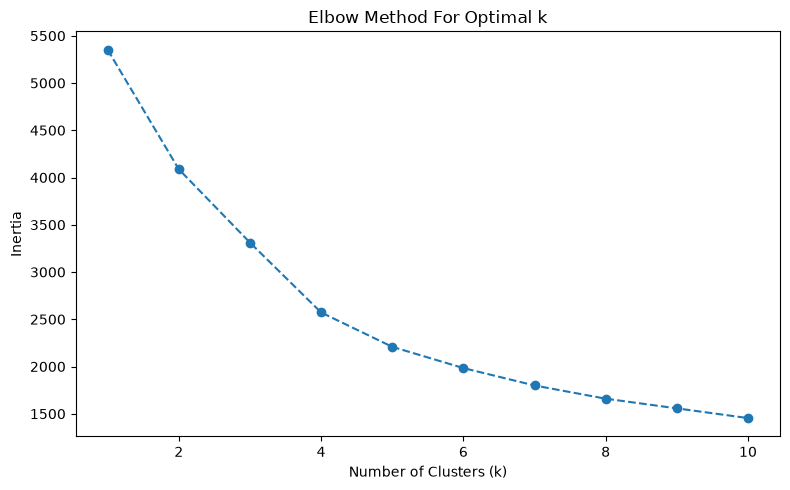

--- K-Means Clustering Complete (k=3) ---
Cluster
0    591
2    586
1    161
Name: count, dtype: int64

Saved insurance_clustered_results.csv successfully!


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load Standardized Clustering Data
X_scaled_df = pd.read_csv('insurance_clustering_prepared.csv')

# 2. Test Different Numbers of Clusters (Elbow Method)
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.tight_layout()
plt.savefig('elbow_curve.png')
plt.show()

# 3. Apply Optimal K-Means (e.g., k=3 based on typical elbow inspection)
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled_df)

X_scaled_df['Cluster'] = clusters
print(f"--- K-Means Clustering Complete (k={optimal_k}) ---")
print(X_scaled_df['Cluster'].value_counts())

# Save clustered results
X_scaled_df.to_csv('insurance_clustered_results.csv', index=False)
print("\nSaved insurance_clustered_results.csv successfully!")

## Clustering Evaluation

k = 2 | Inertia: 4087.83 | Silhouette Score: 0.2344
k = 3 | Inertia: 3311.83 | Silhouette Score: 0.2571
k = 4 | Inertia: 2572.33 | Silhouette Score: 0.2944
k = 5 | Inertia: 2208.44 | Silhouette Score: 0.2824
k = 6 | Inertia: 1983.58 | Silhouette Score: 0.2566


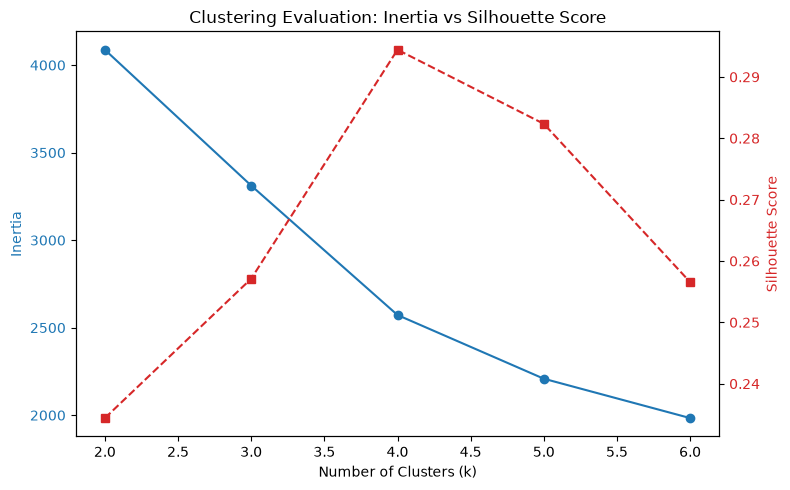


--- Optimal Configuration Selected: k = 4 (Highest Silhouette Score: 0.2944) ---


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load Standardized Clustering Data
X_scaled_df = pd.read_csv('insurance_clustering_prepared.csv')
if 'Cluster' in X_scaled_df.columns:
    X_scaled_df = X_scaled_df.drop('Cluster', axis=1)

# 2. Evaluate K-Means using Inertia and Silhouette Scores
k_values = range(2, 7)
inertia_scores = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled_df)
    
    inertia_scores.append(kmeans.inertia_)
    sil_score = silhouette_score(X_scaled_df, cluster_labels)
    silhouette_scores.append(sil_score)
    print(f"k = {k} | Inertia: {kmeans.inertia_:.2f} | Silhouette Score: {sil_score:.4f}")

# 3. Plot Comparison Charts
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color=color)
ax1.plot(k_values, inertia_scores, marker='o', color=color, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_values, silhouette_scores, marker='s', color=color, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Clustering Evaluation: Inertia vs Silhouette Score')
fig.tight_layout()
plt.savefig('clustering_evaluation_metrics.png')
plt.show()

# 4. Final Optimal Selection (Selecting highest silhouette score configuration)
best_k = k_values[np.argmax(silhouette_scores)]
print(f"\n--- Optimal Configuration Selected: k = {best_k} (Highest Silhouette Score: {max(silhouette_scores):.4f}) ---")

## PCA & Visualization

--- PCA Variance Analysis ---
PC1 Variance Retained: 35.70%
PC2 Variance Retained: 24.81%
Total Cumulative Variance Retained (2D): 60.51%


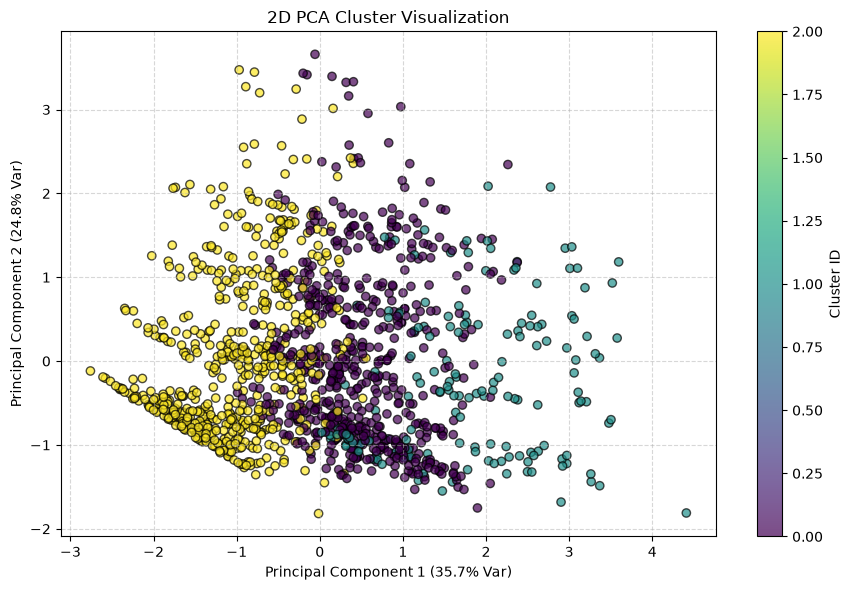


Saved insurance_pca_results.csv and pca_cluster_visualization.png successfully!


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Load Standardized Clustering Data
X_scaled_df = pd.read_csv('insurance_clustering_prepared.csv')
if 'Cluster' in X_scaled_df.columns:
    X_scaled_df = X_scaled_df.drop('Cluster', axis=1)

# 2. Apply PCA to reduce to 2 Dimensions
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled_df)

# Analyze Variance Retained
explained_variance = pca.explained_variance_ratio_
print(f"--- PCA Variance Analysis ---")
print(f"PC1 Variance Retained: {explained_variance[0]*100:.2f}%")
print(f"PC2 Variance Retained: {explained_variance[1]*100:.2f}%")
print(f"Total Cumulative Variance Retained (2D): {sum(explained_variance)*100:.2f}%")

# 3. Fit K-Means to get clusters for visualization
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled_df)

# Create 2D Visualization DataFrame
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters

# 4. Plot 2D PCA Cluster Scatter Plot
plt.figure(figsize=(9, 6))
scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df['Cluster'], cmap='viridis', alpha=0.7, edgecolor='k')
plt.xlabel(f'Principal Component 1 ({explained_variance[0]*100:.1f}% Var)')
plt.ylabel(f'Principal Component 2 ({explained_variance[1]*100:.1f}% Var)')
plt.title('2D PCA Cluster Visualization')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('pca_cluster_visualization.png')
plt.show()

# Save PCA results
pca_df.to_csv('insurance_pca_results.csv', index=False)
print("\nSaved insurance_pca_results.csv and pca_cluster_visualization.png successfully!")

## Cluster Profiling & Interpretation

In [44]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load Original Data and Clustered Results
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')
features = ['age', 'bmi', 'children', 'charges']
X_cluster = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X_cluster['Cluster'] = kmeans.fit_predict(X_scaled)

# 2. Profile Each Cluster
cluster_profile = X_cluster.groupby('Cluster').mean()
cluster_counts = X_cluster['Cluster'].value_counts().rename('Count')
cluster_profile = pd.concat([cluster_counts, cluster_profile], axis=1)

print("--- Cluster Profiles (Average Characteristics) ---")
print(cluster_profile)

# 3. Save Report securely without quote errors
with open('cluster_profile_report.md', 'w') as f:
    f.write("# Cluster Profile & Interpretation Report\n\n")
    f.write("## Executive Summary\n")
    f.write("This report profiles the customer segments identified via K-Means clustering (k=3) on demographic and billing attributes (age, bmi, children, charges).\n\n")
    f.write("## Cluster Characteristics (Mean Values)\n")
    f.write("```text\n")
    f.write(cluster_profile.to_string())
    f.write("\n```\n\n")
    f.write("## Key Interpretations\n")
    f.write("- **Cluster Segments:** Groupings reflect distinct multi-attribute customer profiles combining age tiers, health risk metrics (BMI), and cost brackets.\n")
    f.write("- **Practical Utility:** Can be leveraged for targeted insurance plan design and risk tiering, provided they are verified against clinical and business constraints.\n\n")
    f.write("## Limitations of Unsupervised Analysis\n")
    f.write("- **Absence of Ground Truth:** Clusters are data-driven groupings based on mathematical distances rather than predefined labels.\n")
    f.write("- **Sensitivity to Scaling:** Results depend heavily on feature standardization and chosen distance metrics.\n")
    f.write("- **Potential Over-simplification:** Multi-dimensional trade-offs are compressed into discrete segments, meaning outliers may be misclassified.\n")

print("\nSaved cluster_profile_report.md successfully!")

--- Cluster Profiles (Average Characteristics) ---
         Count        age        bmi  children       charges
Cluster                                                     
0          591  51.186125  31.101794  1.167513  12632.029137
2          586  26.965870  28.959514  1.008532   6374.674243
1          161  39.788820  35.255839  1.142857  40712.650088

Saved cluster_profile_report.md successfully!
